In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle, ConnectionPatch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.colors import LinearSegmentedColormap

In [2]:
def agrupar_em_dataframes(df, col_idx=3, tol=0.2):
    if df.empty:
        return []

    grupos = []

    for idx, linha in df.iterrows():
        valor = linha.iloc[col_idx]
        inserido = False

        for grupo in grupos:
            referencia = df.iloc[grupo[0], col_idx]
            if abs(valor - referencia) <= tol:
                grupo.append(idx)
                inserido = True
                break

        if not inserido:
            grupos.append([idx])

    return [df.loc[g].reset_index(drop=True) for g in grupos]


In [ ]:
#parameters plot
def plot_params(fontsize=18, tick_labelsize=12, legend_fontsize=18):
    """
    Update the parameters of the plot.

    Returns
    -------
    cmap : string
        The color map used in the colored plots.
    """
    plt.clf()
    plt.rc('font', size=fontsize)
    plt.rc('xtick', labelsize=tick_labelsize)
    plt.rc('ytick', labelsize=tick_labelsize)
    plt.rc('legend', fontsize=legend_fontsize)
    plt.rc('text', usetex=False)#alterado
    font = {'family' : 'stix'}
    plt.rc('font', **font)
    mpl.rcParams["font.family"] = "STIXGeneral" #adcionei
    plt.rcParams["mathtext.fontset"] = "stix"
    mpl.rcParams['axes.linewidth'] = 1.3 #set the value globally
    plt.rc('xtick.major', size=8, width=1.3)
    plt.rc('ytick.major', size=8, width=1.3)

(3, 12)
(1, 13)
(1, 16)
(2, 11)
(2, 13)
(1, 16)
(1, 13)
(3, 12)
(2, 11)
(2, 13)
(1, 13)
(1, 16)
(3, 12)
(2, 11)
(2, 13)


<Figure size 640x480 with 0 Axes>

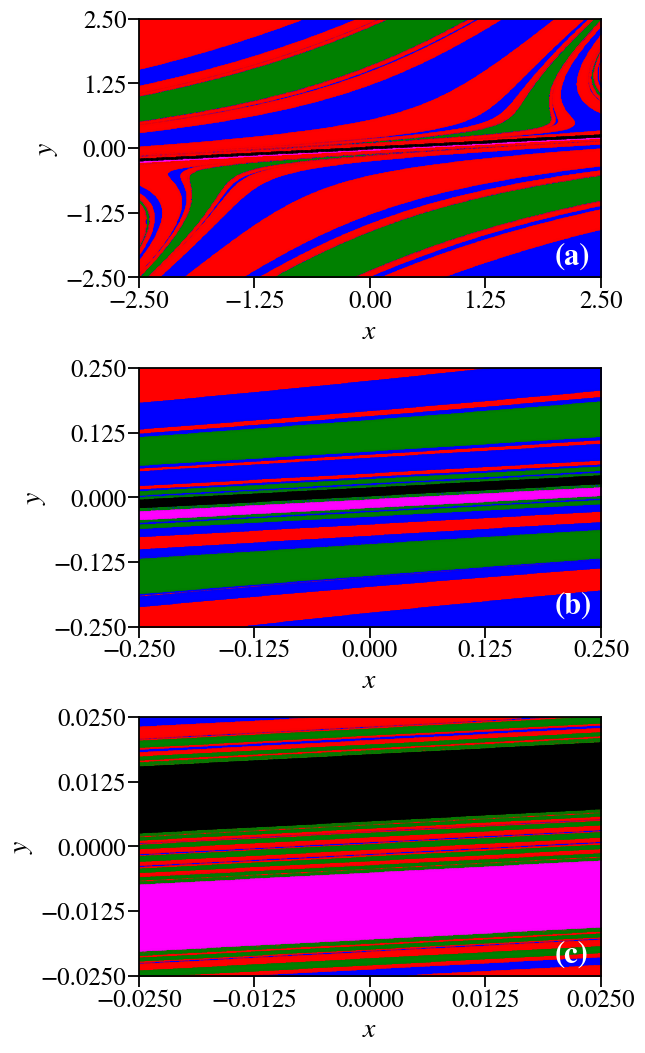

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
# Configurações gerais
# ======================================================
# modificado (mantido)
plot_params(
    fontsize=28,
    tick_labelsize=18,
    legend_fontsize=18
)

# ======================================================
# Pasta dos dados
# ======================================================
#modificado
pasta = (
    "../../bif_and_basins/csv_zoom_basin/"
)

# ======================================================
# Arquivos
# ======================================================
#modificado
arquivos = [
    "0basin[3.500]_zoom.bin",
    "1basin[3.500]_zoom.bin",
    "2basin[3.500]_zoom.bin"    
]

# ======================================================
# Cores fixas
# ======================================================
#modificado
cores = {
        (1,16): "red",
        (1,13): "blue",
        (2,11): "magenta",
        (2,13): "black",
        (3,12): "green"
}

# ======================================================
# Figura
# ======================================================
# modificado
fig, ax = plt.subplots(
    3,
    1,
    figsize=(6, 11)
)

# ======================================================
# Painel (a)
# Diagrama de bifurcação
# ======================================================
#modificado
arquivo = arquivos[0]

    # --------------------------------------------------
    # Leitura
    # --------------------------------------------------

caminho = pasta + arquivo


dados = np.fromfile(caminho, dtype = np.float64)
dados = pd.DataFrame(dados.reshape(-1,8))

meus_arrays1 = agrupar_em_dataframes(dados)

for i in range(len(meus_arrays1)):
    meus_arrays1[i] = meus_arrays1[i].to_numpy()
    print((int(meus_arrays1[i][0,2]),int(meus_arrays1[i][0,3]//1)))
    col = cores[(int(meus_arrays1[i][0,2]),int(meus_arrays1[i][0,3]//1))]
        



    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    ax[0].scatter(
        meus_arrays1[i][:, 0],          # x
        meus_arrays1[i][:, 1],          # y
        s=0.05,
        color=col
        )

# ------------------------------------------------------
# Limites
# ------------------------------------------------------
#modificado
ax[0].set_xlim(-2.5, 2.5)
ax[0].set_ylim(-2.5, 2.5)

ax[0].set_yticks(
    [-2.5, -1.25,0, 1.25, 2.5]
)
ax[0].set_xticks(
    [-2.5, -1.25,0, 1.25, 2.5]
)

# ------------------------------------------------------
# Labels
# ------------------------------------------------------
#modificado
ax[0].set_xlabel(
    r"$x$",
    fontsize=20
)

ax[0].set_ylabel(
    r"$y$",
    fontsize=20
)

# ------------------------------------------------------
# Label (a)
# ------------------------------------------------------
#modificado
ax[0].text(
    0.9,
    0.05,
    r"(a)",  
    transform=ax[0].transAxes,
    fontsize=22,
    fontweight="bold",
    color="white",
)


# ======================================================
# Painel (b)
# Atratores
# ======================================================
arquivo = arquivos[1]

    # --------------------------------------------------
    # Leitura
    # --------------------------------------------------

caminho = pasta + arquivo


dados = np.fromfile(caminho, dtype = np.float64)
dados = pd.DataFrame(dados.reshape(-1,8))

meus_arrays1 = agrupar_em_dataframes(dados)

for i in range(len(meus_arrays1)):
    meus_arrays1[i] = meus_arrays1[i].to_numpy()
    print((int(meus_arrays1[i][0,2]),int(meus_arrays1[i][0,3]//1)))
    col = cores[(int(meus_arrays1[i][0,2]),int(meus_arrays1[i][0,3]//1))]
        



    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    ax[1].scatter(
        meus_arrays1[i][:, 0],          # x
        meus_arrays1[i][:, 1],          # y
        s=0.05,
        color=col
        )


# ======================================================
# Configurações do painel (b)
# ======================================================

#-------------------------------------------------------
#Limites
#-------------------------------------------------------
ax[1].set_xlim(-0.25, 0.25)
ax[1].set_ylim(-0.25, 0.25)

ax[1].set_yticks(
    [-0.25, -0.125,0, 0.125, 0.25]
)
ax[1].set_xticks(
    [-0.25, -0.125,0, 0.125, 0.25]
)


ax[1].set_xlabel(
    r"$x$",
    fontsize=20
)

ax[1].set_ylabel(
    r"$y$",
    fontsize=20
)

# ------------------------------------------------------
# Label (b)
# ------------------------------------------------------

ax[1].text(
    0.9,
    0.05,
    r"(b)",
    transform=ax[1].transAxes,
    fontsize=22,
    fontweight="bold",
    color = "white"
)

# ======================================================
# Painel (c)
# Atratores
# ======================================================
arquivo = arquivos[2]

    # --------------------------------------------------
    # Leitura
    # --------------------------------------------------

caminho = pasta + arquivo


dados = np.fromfile(caminho, dtype = np.float64)
dados = pd.DataFrame(dados.reshape(-1,8))

meus_arrays1 = agrupar_em_dataframes(dados)

for i in range(len(meus_arrays1)):
    meus_arrays1[i] = meus_arrays1[i].to_numpy()
    print((int(meus_arrays1[i][0,2]),int(meus_arrays1[i][0,3]//1)))
    col = cores[(int(meus_arrays1[i][0,2]),int(meus_arrays1[i][0,3]//1))]
        



    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    ax[2].scatter(
        meus_arrays1[i][:, 0],          # x
        meus_arrays1[i][:, 1],          # y
        s=0.05,
        color=col
        )


# ======================================================
# Configurações do painel (b)
# ======================================================

#-------------------------------------------------------
#Limites
#-------------------------------------------------------
ax[2].set_xlim(-0.025, 0.025)
ax[2].set_ylim(-0.025, 0.025)

ax[2].set_yticks(
    [-0.025, -0.0125,0, 0.0125, 0.025]
)
ax[2].set_xticks(
    [-0.025, -0.0125,0, 0.0125, 0.025]
)


ax[2].set_xlabel(
    r"$x$",
    fontsize=20
)

ax[2].set_ylabel(
    r"$y$",
    fontsize=20
)

# ------------------------------------------------------
# Label (c)
# ------------------------------------------------------

ax[2].text(
    0.9,
    0.05,
    r"(c)",
    transform=ax[2].transAxes,
    fontsize=22,
    fontweight="bold",
    color = "white"
)

# ======================================================
# Ajustes dos ticks
# ======================================================

for a in ax:

    a.tick_params(
        axis="x",
        pad=1
    )

    a.tick_params(
        axis="y",
        pad=1
    )



# ======================================================
# Layout
# ======================================================

#plt.tight_layout()
fig.subplots_adjust(
    left=0.18,  # Espaço na esquerda para os rótulos do eixo Y
    right=0.95,  # Espaço na direita
    bottom=0.08,  # Espaço na base para os rótulos do eixo X
    top=0.95,  # Espaço no topo
    hspace=0.35,  # Espaço vertical ENTRE os subplots
)

# ======================================================
# Salvar
# ======================================================

plt.savefig(
    "fig4.jpeg",
    format="jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()